DATA CLEANING

PART 2: CURATED LAYER ------------------------------------------------------------------------------------------------------------------------

Begin Our PySpark Session.

In [2]:
from pyspark.sql import SparkSession, functions as F

spark = (
    SparkSession.builder.appName("Data Cleaning")
    .config("spark.sql.repl.eagerEval.enabled", True)
    .config("spark.sql.parquet.cacheMetadata", "true")
    .config("spark.sql.session.timeZone", "Etc/UTC")
    .config('spark.driver.memory', '8g')
    .config('spark.executor.memory', '4g')
    .getOrCreate()
)
# Silence any WARN-level logs from this point forth.
spark.sparkContext.setLogLevel("ERROR")

Lets define the null check function once more.

In [3]:
from functools import reduce

def null_check(df):
    has_null_condition = reduce(
        lambda acc, c: acc | F.col(c).isNull(),
        df.columns,
        F.lit(False)
    )

    # Count total rows, rows with atleast one null and count how many nulls occur per
    # data field.
    summary = df.agg(
        F.count(F.lit(1)).alias("total_rows"),
        F.sum(has_null_condition.cast("int")).alias("rows_with_at_least_one_null"),
        *[F.sum(F.col(c).isNull().cast("int")).alias(f"null_{c}") for c in df.columns]
    ).collect()[0]
    
    total = summary["total_rows"]
    rows_with_at_least_one_null = summary["rows_with_at_least_one_null"]
    
    print(f"Total rows: {total:,}")
    print(f"Rows with at least one null value: {rows_with_at_least_one_null:,}")
    print(f"Percentage of rows with atleast one NULL: {round(100 * rows_with_at_least_one_null / total, 2)}%")
    print()
    for c in df.columns:
        print(f"{c:25s} {summary[f'null_{c}']:>12,}")

<br>
<br>
<br>

### Dealing with `structured_features`

Lets clean up our `structued_features` descriptions so they are all comma seperated properly and consistent with other rows.

In [35]:
raw_path = "../../rea_data/raw/vic_rentals_raw.parquet"

df_raw = spark.read.parquet(raw_path)

print(f"Shape: {df_raw.count():,} rows, {len(df_raw.columns)} columns")

In [36]:
# This error was found upon visual inspection of the csv
row = df_raw.filter(F.col("listing_id") == "17747859")
row.show(truncate=False, vertical=True)

-RECORD 0--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
 listing_id          | 17747859                                                                                                                                                                                                                                                                                                                                  
 suburb              | DOCKLANDS                                                                                                                                                                                                                                                                    

In [37]:
df_raw = df_raw.withColumn(
    "structured_features",
    F.regexp_replace(
        F.col("structured_features"),
        r"[\r\n]+-\s*",   # matches \r\n or \n followed by "- " (the bullet style)
        ", "              # replace with a plain comma separator
    )
)

In [38]:
row = df_raw.filter(F.col("listing_id") == "17747859")
row.show(truncate=False, vertical=True)

-RECORD 0----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
 listing_id          | 17747859                                                                                                                                                                                                                                                                                                                  
 suburb              | DOCKLANDS                                                                                                                                                                                                                                                                                                    

We used a specific case ("listing_id=17747859") to illustrate our point, but must check that it has been fixed for every such row.

In [39]:
remaining_bullets = df_raw.filter(
    F.col("structured_features").rlike(r"[\r\n]-\s")
)
remaining_bullets.count()

0

In [40]:
from pyspark.ml.feature import CountVectorizer

# --- 1. Strip section headers (e.g. "BUILDING AMENITIES") before splitting ---
header_pattern = r"(BUILDING AMENITIES|INDOOR FEATURES|OUTDOOR FEATURES|CLIMATE CONTROL)\s*,?\s*"
df_raw = df_raw.withColumn(
    "structured_features_clean",
    F.regexp_replace(F.col("structured_features"), header_pattern, "")
)

# --- 2. Split into array, trim whitespace, lowercase each element ---
df_raw = df_raw.withColumn(
    "features_array",
    F.expr("""
        transform(
            split(trim(structured_features_clean), ','),
            x -> lower(trim(x))
        )
    """)
).withColumn(
    "features_array",
    F.expr("filter(features_array, x -> x != '')")  # drop empty strings from trailing commas
)

# --- Explode features_array into one row per (listing, feature), then count distinct values ---
feature_counts = (
    df_raw
    .select(F.explode("features_array").alias("feature"))
    .groupBy("feature")
    .count()
    .orderBy(F.desc("count"))
)

total_unique = feature_counts.count()
print(f"Total unique feature strings: {total_unique}")

feature_counts.show(total_unique, vertical = True, truncate=True)

row = df_raw.filter(F.col("listing_id") == "17747859")
row.show(truncate=True, vertical=True)

Total unique feature strings: 532
-RECORD 0-----------------------
 feature | built in wardrobes   
 count   | 6690                 
-RECORD 1-----------------------
 feature | heating              
 count   | 5710                 
-RECORD 2-----------------------
 feature | dishwasher           
 count   | 5456                 
-RECORD 3-----------------------
 feature | secure parking       
 count   | 4966                 
-RECORD 4-----------------------
 feature | internal laundry     
 count   | 3993                 
-RECORD 5-----------------------
 feature | air conditioning     
 count   | 3796                 
-RECORD 6-----------------------
 feature | balcony / deck       
 count   | 2509                 
-RECORD 7-----------------------
 feature | gas                  
 count   | 2421                 
-RECORD 8-----------------------
 feature | floorboards          
 count   | 1904                 
-RECORD 9-----------------------
 feature | bath                 
 count   

In [41]:
# --- Junk filter: flag likely listing-description leakage vs genuine short features ---

feature_counts_flagged = (
    feature_counts
    .withColumn("word_count", F.size(F.split(F.col("feature"), r"\s+")))
    .withColumn("char_length", F.length(F.col("feature")))
    .withColumn(
        "is_likely_junk",
        (F.col("word_count") > 6) |                                  # long free-text phrases
        (F.col("char_length") > 45) |                                 # long strings generally
        F.col("feature").rlike(r"\.\s|,\s.*,\s") |                    # embedded sentence punctuation
        F.col("feature").rlike(r"\b(will be|please|provided|included at|works during|suitable for)\b")
    )
)

# --- Review what gets flagged before deleting anything ---
print("=== Flagged as likely junk (review before dropping) ===")
feature_counts_flagged.filter("is_likely_junk").orderBy(F.desc("count")).show(100, truncate=False)

print("=== Kept as likely genuine features ===")
feature_counts_flagged.filter("NOT is_likely_junk").orderBy(F.desc("count")).show(100, truncate=False)

n_junk = feature_counts_flagged.filter("is_likely_junk").count()
n_kept = feature_counts_flagged.filter("NOT is_likely_junk").count()
print(f"\nFlagged as junk: {n_junk} / {n_junk + n_kept} unique features")

=== Flagged as likely junk (review before dropping) ===
+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+-----+----------+-----------+--------------+
|feature                                                                                                                                                                                                                                |count|word_count|char_length|is_likely_junk|
+---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+-----+----------+-----------+--------------+
|energy eff. rating: 6                                                                                        

In [42]:
# --- Extract "energy eff. rating: X" into a proper numeric column ---

df_raw = df_raw.withColumn(
    "energy_eff_rating",
    F.expr("""
        aggregate(
            filter(features_array, x -> x rlike 'energy eff\\\\. rating: [0-9.]+'),
            cast(null as double),
            (acc, x) -> try_cast(regexp_extract(x, 'energy eff\\\\. rating: ([0-9.]+)', 1) as double)
        )
    """)
)

# --- Remove the raw "energy eff. rating: X" strings from features_array now that they're captured ---
df_raw = df_raw.withColumn(
    "features_array",
    F.expr("filter(features_array, x -> NOT (x rlike 'energy eff\\\\. rating: [0-9.]+'))")
)

# --- Sanity check ---
df_raw.select("listing_id", "energy_eff_rating").filter(F.col("energy_eff_rating").isNotNull()).show(15)
df_raw.select("energy_eff_rating").summary("count", "min", "max", "mean").show()

+----------+-----------------+
|listing_id|energy_eff_rating|
+----------+-----------------+
|  17703824|              6.0|
|  17391686|              6.0|
|  17743107|              7.0|
|  17561797|              5.0|
|  17722774|              8.5|
|  17493594|              6.0|
|  17513777|              6.0|
|  17514065|              6.0|
|  17571887|              6.0|
|  17666119|              6.0|
|  17714175|              6.0|
|  17733347|              6.0|
|  17649973|              5.0|
|  17741703|              7.0|
|  17725067|              7.0|
+----------+-----------------+
only showing top 15 rows
+-------+-----------------+
|summary|energy_eff_rating|
+-------+-----------------+
|  count|               51|
|    min|              0.5|
|    max|              8.6|
|   mean| 5.74313725490196|
+-------+-----------------+



In [43]:
# Collect feature counts to pandas (only 532 rows — trivial size)
pdf_counts = feature_counts.toPandas()

# pip install rapidfuzz --break-system-packages   # if not already installed
from rapidfuzz import fuzz, process

# --- Exclude features with digits or "un-" prefixes from fuzzy clustering ---
# These need separate handling: digits -> numeric columns, un-prefixed -> opposite category, not a fuzzy merge
exclude_mask = pdf_counts["feature"].str.contains(r"\d", regex=True) | pdf_counts["feature"].str.match(r"^un\w+")
excluded_df = pdf_counts[exclude_mask]
fuzzy_df = pdf_counts[~exclude_mask]

print(f"Excluded from fuzzy clustering: {len(excluded_df)} (review separately)")
excluded_df.sort_values("count", ascending=False)

Excluded from fuzzy clustering: 52 (review separately)


,feature,count
35,pool/spa count: 0,253
120,energy eff. rating: 6,20
154,garage spaces: 1,10
179,energy eff. rating: 5,7
183,energy eff. rating: 7,6
184,unfurnished,6
185,car spaces: 1,6
215,garage spaces: 2,4
219,energy eff. rating: 6.5,4
227,carport spaces: 1,4


In [44]:
features = fuzzy_df["feature"].tolist()
counts = dict(zip(fuzzy_df["feature"], fuzzy_df["count"]))

clusters = {}
assigned = set()

# Process from most-frequent to least, so common terms become canonical cluster labels
for feat in sorted(features, key=lambda f: -counts[f]):
    if feat in assigned:
        continue
    matches = process.extract(
        feat, features, scorer=fuzz.token_sort_ratio, limit=10, score_cutoff=87
    )
    group = [m[0] for m in matches if m[0] not in assigned]
    if len(group) > 1:
        clusters[feat] = group          # feat = canonical name (most frequent form)
        assigned.update(group)

# Show candidate clusters for manual review
for canonical, group in clusters.items():
    if len(group) > 1:
        print(f"{canonical!r}  <-  {group}")

'internal laundry'  <-  ['internal laundry', 'laundry: internal']
'balcony / deck'  <-  ['balcony / deck', 'deck / balcony']
'remote garage'  <-  ['remote garage', 'garage remote']
'ducted heating'  <-  ['ducted heating', 'gas ducted heating']
'split system heating'  <-  ['split system heating', 'split system (heating)', 'split-system heating']
'outdoor entertainment area'  <-  ['outdoor entertainment area', 'outdoor entertaining area', 'outdoor entertainment']
'courtyard'  <-  ['courtyard', 'coutyard']
'split system air con'  <-  ['split system air con', 'split system aircon', 'split system (air con)', 'split-system air con']
'split system air conditioning'  <-  ['split system air conditioning', 'split system airconditioning', 'split-system air conditioning', 'split-system air-conditioning']
'gas heating'  <-  ['gas heating', 'heating: gas']
'cooking: gas hotplates and electric oven'  <-  ['cooking: gas hotplates and electric oven', 'cooking: electric hotplates & gas oven', 'cooking: 

In [45]:
merge_map = {
    # --- Formatting/spelling variants -> canonical name ---
    "laundry: internal": "internal laundry",
    "deck / balcony": "balcony / deck",
    "garage remote": "remote garage",
    "gas ducted heating": "ducted heating",
    "split system (heating)": "split system heating",
    "split-system heating": "split system heating",
    "outdoor entertaining area": "outdoor entertainment area",
    "outdoor entertainment": "outdoor entertainment area",
    "coutyard": "courtyard",

    # split system air con group (merged together — "air con" == "air conditioning")
    "split system aircon": "split system air conditioning",
    "split system (air con)": "split system air conditioning",
    "split-system air con": "split system air conditioning",
    "split system air con": "split system air conditioning",
    "split system airconditioning": "split system air conditioning",
    "split-system air conditioning": "split system air conditioning",
    "split-system air-conditioning": "split system air conditioning",
    "split system ac": "split system air conditioning",
    "split system": "split system air conditioning",

    "heating: gas": "gas heating",
    "cooking: electric hotplates & gas oven": "cooking: gas hotplates and electric oven",
    "cooking: electric hotplates & oven": "cooking: gas hotplates and electric oven",
    "cooking: gas oven and hotplates": "cooking: gas hotplates and electric oven",
    "reverse cycle aircon": "reverse cycle air con",
    "ducted air-conditioning": "ducted air conditioning",
    "tennis courts": "tennis court",
    "spa (inside)": "inside spa",
    "modern kitchen": "kitchen: modern",
    "basement car parking": "car parking - basement",
    "living areas": "living area",
    "hot water service": "gas hot water service",  # NOTE: see caveat below — fuel type unconfirmed
    "kitchen: renovated": "renovated kitchen",
    "laundry: separate": "separate laundry",

    # in-ground pool group (kept SEPARATE from above-ground — see correction below)
    "pool (inground)": "inground pool",
    "pool (in ground)": "inground pool",

    # above-ground pool group (corrected: no longer merged with "below ground")
    "pool (above ground)": "above ground pool",
    "above-ground pool": "above ground pool",

    "heating electric": "electric heating",
    "heating: electric": "electric heating",
    "split system heating / cooling": "split system heating and cooling",
    "split system heating & cooling": "split system heating and cooling",
    "hyrdonic heating": "hydronic heating",
    "heating other": "heating: other",
    "carports": "carport",
    "electrical cooktop": "electric cooktop",
    "backyard access": "access to backyard",

    # euro laundry group (merged together — these are all the same category)
    "euro laundry": "laundry: euro",
    "laundry: european laundry": "laundry: euro",
    "laundry: european": "laundry: euro",
    "european laundry": "laundry: euro",

    "reverse cycle ac": "reverse cycle",
    "integrated fridge/freezer": "intergrated frige/freezer",  # NOTE: canonical form has a typo — see below
}

In [46]:
from itertools import chain

# Build a Spark map literal from the Python merge_map dict
mapping_col = F.create_map([F.lit(x) for pair in merge_map.items() for x in pair])

# Apply it: for each element in features_array, look it up in the map;
# if not found (not in merge_map), keep the original value via coalesce
df_raw = df_raw.withColumn(
    "features_array",
    F.transform("features_array", lambda x: F.coalesce(mapping_col[x], x))
)

In [47]:
feature_counts_after = (
    df_raw
    .select(F.explode("features_array").alias("feature"))
    .groupBy("feature")
    .count()
    .orderBy(F.desc("count"))
)
print(f"Total unique feature strings after merge: {feature_counts_after.count()}")
feature_counts_after.show(50, truncate=False)

Total unique feature strings after merge: 466
+-----------------------------+-----+
|feature                      |count|
+-----------------------------+-----+
|built in wardrobes           |6690 |
|heating                      |5710 |
|dishwasher                   |5456 |
|secure parking               |4966 |
|internal laundry             |3997 |
|air conditioning             |3796 |
|balcony / deck               |2510 |
|gas                          |2421 |
|floorboards                  |1904 |
|bath                         |1881 |
|intercom                     |1629 |
|ensuite                      |1621 |
|fully fenced                 |1433 |
|study                        |1280 |
|furnished                    |1128 |
|split system air conditioning|1089 |
|pets allowed                 |1047 |
|close to shops               |965  |
|split system heating         |948  |
|close to transport           |947  |
|close to schools             |932  |
|remote garage                |919  |
|she

In [48]:
from pyspark.sql.types import ArrayType, StringType

df_raw = df_raw.withColumn(
    "features_array",
    F.coalesce(F.col("features_array"), F.array().cast(ArrayType(StringType())))
)

# Confirm no nulls remain before fitting
null_count = df_raw.filter(F.col("features_array").isNull()).count()
print(f"Remaining nulls in features_array: {null_count}")

Remaining nulls in features_array: 0


In [49]:
from pyspark.ml.feature import CountVectorizer

cv = CountVectorizer(
    inputCol="features_array",
    outputCol="features_vector",
    binary=True,
    minDF=100
)
cv_model = cv.fit(df_raw)
df_raw = cv_model.transform(df_raw)

print(f"Vocabulary size after minDF filter: {len(cv_model.vocabulary)}")
print(cv_model.vocabulary)

Vocabulary size after minDF filter: 52
['built in wardrobes', 'heating', 'dishwasher', 'secure parking', 'internal laundry', 'air conditioning', 'balcony / deck', 'gas', 'floorboards', 'bath', 'intercom', 'ensuite', 'fully fenced', 'study', 'furnished', 'split system air conditioning', 'pets allowed', 'close to shops', 'split system heating', 'close to transport', 'close to schools', 'remote garage', 'shed', 'ducted heating', 'garden / courtyard', 'gym', 'outdoor entertainment area', 'balcony', 'broadband internet access', 'alarm system', 'swimming pool', 'courtyard', 'solar panels', 'fireplace(s)', 'pool/spa count: 0', 'bathtub', 'ensuite(s)', 'carpeted', 'gas appliances', 'evaporative cooling', 'openable windows', 'broadband', 'rumpus room', 'ducted cooling', 'broadband internet available', 'city views', 'gas heating', 'deck', 'laundry', 'air-conditioner', 'separate dining room', 'double glazed windows']


In [50]:
from pyspark.ml.functions import vector_to_array

# Convert the sparse vector into a plain array column
df_raw = df_raw.withColumn("features_array_ohe", vector_to_array("features_vector"))

# Create one binary column per vocabulary term, named cleanly for readability
vocab = cv_model.vocabulary  # list of 52 feature names, in vector-index order

for i, feature_name in enumerate(vocab):
    col_name = "feat_" + feature_name.lower().replace(" ", "_").replace("/", "_").replace("(", "").replace(")", "").replace(":", "").replace("-", "_")
    df_raw = df_raw.withColumn(col_name, F.col("features_array_ohe")[i].cast("int"))

# Drop intermediate columns you no longer need
df_raw = df_raw.drop("features_vector", "features_array_ohe")

print(f"Added {len(vocab)} one-hot feature columns.")
df_raw.select([c for c in df_raw.columns if c.startswith("feat_")]).show(5)

Added 52 one-hot feature columns.
+-----------------------+------------+---------------+-------------------+---------------------+---------------------+-------------------+--------+----------------+---------+-------------+------------+-----------------+----------+--------------+----------------------------------+-----------------+-------------------+-------------------------+-----------------------+---------------------+------------------+---------+-------------------+-----------------------+--------+-------------------------------+------------+------------------------------+-----------------+------------------+--------------+-----------------+---------------+---------------------+------------+-------------+-------------+-------------------+------------------------+---------------------+--------------+----------------+-------------------+---------------------------------+---------------+----------------+---------+------------+--------------------+-------------------------+-------------

In [53]:
## Removing any redundant columns that are no longer needed after one-hot encoding
df_raw = df_raw.drop("features_array", "structured_features_clean")

In [54]:
null_check(df_raw)

Total rows: 12,717
Rows with at least one null value: 12,717
Percentage of rows with atleast one NULL: 100.0%

listing_id                           0
suburb                               0
postcode                             0
weekly_rent                        279
bond                               782
available_date                     136
date_listed                          4
days_listed                          4
bedrooms                           125
bathrooms                           51
carspaces                        1,803
property_type                        0
address                            104
lat                                  4
lon                                  4
scraped_date                         0
domain_page_id                       1
property_id                     10,145
photo_count                          4
video_count                          4
floorplans_count                     4
virtual_tour                         4
primary_type                   

 *Lets persist what we have done with `structued_features` for ease of use in further data cleaning*

In [4]:
# Save the cleaned DataFrame to Parquet format
output_path = "../../rea_data/curated/vic_rentals_curated_1.parquet"

df_raw.write.mode("overwrite").parquet(output_path)

print(f"Shape: {df_raw.count():,} rows, {len(df_raw.columns)} columns")

NameError: name 'df_raw' is not defined

<br>
<br>
<br>

### Dealing with Non-Residential Buildings

In [69]:
curated_one_path = "../../rea_data/curated/vic_rentals_curated_1.parquet"

df_curated_one = spark.read.parquet(curated_one_path)

The assignment brief asks us to predict rents for residential properties and apartments, and to find liveable, affordable suburbs. Things like a car space, Vacant land *etc.* isn't somewhere anyone lives, so it doesn't belong in those answers. 

So we should investigate the different `property_type`'s that appear in this data set and remove those that are irrelevant.

In [70]:
# What property types are in the data 
df_curated_one.groupBy("property_type").agg(
    F.count("*").alias("n"),
).orderBy(F.desc("n")).show(50, truncate=False)

+-----------------------------+----+
|property_type                |n   |
+-----------------------------+----+
|House                        |6589|
|Apartment / Unit / Flat      |4516|
|Townhouse                    |1278|
|Studio                       |209 |
|New Apartments / Off the Plan|45  |
|Villa                        |28  |
|Acreage / Semi-Rural         |13  |
|Semi-Detached                |10  |
|New House & Land             |8   |
|Car Space                    |7   |
|Block of Units               |3   |
|Terrace                      |3   |
|Duplex                       |3   |
|Farm                         |2   |
|Unknown                      |2   |
|Vacant land                  |1   |
+-----------------------------+----+



So, only Car Space (7) and Vacant land (1) need to go. Everything else is somewhere people can live.

In [71]:
non_residential_types = ["Car Space", "Vacant land"]

n_before = df_curated_one.count()

non_res = df_curated_one.filter(F.col("property_type").isin(non_residential_types))
print(f"Non-residential listings removed: {non_res.count():,}")


df_curated_one = df_curated_one.filter(~F.col("property_type").isin(non_residential_types)).cache()
print(f"Remaining: {df_curated_one.count():,} "f"({round(100 * non_res.count() / n_before, 2)}%)")

Non-residential listings removed: 8
Remaining: 12,709 (0.06%)


<br>
<br>
<br>

### Dealing with `weekly_rent` 

Seeing as though `weekly_rent` is our **response variable** (the variable we wish to predict), we must ensure that it contains valid values. Since this is the variable we are trying to predict, missing or invalid values cannot be imputed and should instead be removed.


In [72]:
null_check(df_curated_one)

Total rows: 12,709
Rows with at least one null value: 12,709
Percentage of rows with atleast one NULL: 100.0%

listing_id                           0
suburb                               0
postcode                             0
weekly_rent                        278
bond                               781
available_date                     135
date_listed                          4
days_listed                          4
bedrooms                           119
bathrooms                           45
carspaces                        1,801
property_type                        0
address                            104
lat                                  4
lon                                  4
scraped_date                         0
domain_page_id                       1
property_id                     10,139
photo_count                          4
video_count                          4
floorplans_count                     4
virtual_tour                         4
primary_type                   

Firstly, evident by the previous cell's `null_check`, lets remove all 278 rows where `weekly_rent` is `NULL`

In [73]:
# Drop listings with no weekly_rent (null values)
n_before = df_curated_one.count()

df_curated_one = df_curated_one.filter(F.col("weekly_rent").isNotNull())

n_after = df_curated_one.count()
print(f"Rows before: {n_before:,}")
print(f"Rows after:  {n_after:,}")
print(f"Dropped {n_before - n_after:,} listings with NULL weekly_rent "
      f"({round(100 * (n_before - n_after) / n_before, 2)}%)")

Rows before: 12,709
Rows after:  12,431
Dropped 278 listings with NULL weekly_rent (2.19%)


Furthermore, lets do an analysis on `weekly_rent` values to see which values are plausabile and which are not. This could be as a result of misinputs, bad parsing *etc.*

In [74]:
df_curated_one.agg(
    F.min("weekly_rent").alias("min"),
    F.round(F.mean("weekly_rent"), 2).alias("mean"),
    F.max("weekly_rent").alias("max"),
).show()

+---+-----+--------+
|min| mean|     max|
+---+-----+--------+
|0.0|765.1|808500.0|
+---+-----+--------+



In [75]:
print("=== Top 10 highest weekly_rent ===")
df_curated_one.select("listing_id", "weekly_rent") \
    .orderBy(F.desc("weekly_rent")).show(10)

print("=== Top 10 lowest weekly_rent ===")
df_curated_one.select("listing_id", "weekly_rent") \
    .orderBy(F.asc("weekly_rent")).show(10)

=== Top 10 highest weekly_rent ===
+----------+-----------+
|listing_id|weekly_rent|
+----------+-----------+
|  17697966|   808500.0|
|  17750082|   595000.0|
|  17747509|   315000.0|
|  17712191|    10000.0|
|  17661725|     5866.0|
|  17722803|     5750.0|
|   9287841|     5000.0|
|  17744678|     4500.0|
|  17694334|     4500.0|
|  17460975|     4000.0|
+----------+-----------+
only showing top 10 rows
=== Top 10 lowest weekly_rent ===
+----------+-----------+
|listing_id|weekly_rent|
+----------+-----------+
|  17175722|        0.0|
|  17316329|        0.0|
|  17442602|        0.0|
|  17159699|        0.0|
|  10344261|        0.0|
|  17456126|        0.0|
|  16697431|        0.0|
|  16706257|        0.0|
|  17416575|        0.0|
|  15367349|        0.0|
+----------+-----------+
only showing top 10 rows


First and foremost, its easy to see that the 3 highest weekly rents are most certainly incorrect; most likely the price of the given house/apartment rather than the `weekly_rent`, so we should remove these accordingly. Likewise, any `weekly_rent` that is $=0$ (for whatever reason it may be) is certainly invalid and should also be removed.

Note: As shown by this web page, https://www.domain.com.au/toorak-vic-3142-17712191, the listing with a `weekly_rent` of \$10,000 was found to be a legitimate price.

And so we proceed with said filtering in the following cell:

In [76]:
# --- Remove confirmed misparsed rents (sale prices / concatenated digits) and $0 placeholders ---
misparsed_ids = [17697966, 17750082, 17747509]   # $808,500 / $595,000 / $315,000

n_before = df_curated_one.count()
n_misparsed = df_curated_one.filter(F.col("listing_id").isin(misparsed_ids)).count()
n_zero = df_curated_one.filter(F.col("weekly_rent") == 0).count()

df_curated_one = df_curated_one.filter(
    ~F.col("listing_id").isin(misparsed_ids) & (F.col("weekly_rent") > 0)
)

n_after = df_curated_one.count()
print(f"Removed {n_misparsed} unreasonably high rents")
print(f"Removed {n_zero} listings with weekly_rent = 0")
print(f"Rows: {n_before:,} -> {n_after:,}")

Removed 3 unreasonably high rents
Removed 17 listings with weekly_rent = 0
Rows: 12,431 -> 12,411


In [77]:
df_curated_one.agg(
    F.min("weekly_rent").alias("min"),
    F.round(F.mean("weekly_rent"), 2).alias("mean"),
    F.max("weekly_rent").alias("max"),
).show()

print("=== Top 10 highest weekly_rent ===")
df_curated_one.select("listing_id", "weekly_rent") \
    .orderBy(F.desc("weekly_rent")).show(10)

print("=== Top 10 lowest weekly_rent ===")
df_curated_one.select("listing_id", "weekly_rent") \
    .orderBy(F.asc("weekly_rent")).show(10)

+----+------+-------+
| min|  mean|    max|
+----+------+-------+
|18.0|627.87|10000.0|
+----+------+-------+

=== Top 10 highest weekly_rent ===
+----------+-----------+
|listing_id|weekly_rent|
+----------+-----------+
|  17712191|    10000.0|
|  17661725|     5866.0|
|  17722803|     5750.0|
|   9287841|     5000.0|
|  17694334|     4500.0|
|  17744678|     4500.0|
|  17460975|     4000.0|
|  17750966|     4000.0|
|  14253235|     3900.0|
|  17721041|     3850.0|
+----------+-----------+
only showing top 10 rows
=== Top 10 lowest weekly_rent ===
+----------+-----------+
|listing_id|weekly_rent|
+----------+-----------+
|  13243113|       18.0|
|  12352715|       22.0|
|  16490695|       27.0|
|  12981625|       30.0|
|  12981632|       30.0|
|  16559047|       33.0|
|  10801345|       33.0|
|  12853814|       36.0|
|  17240713|       42.0|
|  16211673|       46.0|
+----------+-----------+
only showing top 10 rows


#### Outlier treatment for `weekly_rent`

Lets now flag outliers using IQR fences on log(weekly_rent), with a multiplier that grows
with sample size, k = √(ln N) − 0.5. With N = 12,411
this gives k = 2.57. On the log scale the distribution is roughly symmetric.

- **Lower fence: $203/week** 86 listings flagged.
  
- **Upper fence: $1,663/week** 137 listings flagged.

**We treat the two tails differently.**

*Low outliers (removed).* Rents below about $200/week are implausible for a
self-contained residential lease in Victoria from our outlier analysis.

*High outliers (kept).* High rents are a genuine part of the Victorian rental market,
not data errors. The flagged listings are concentrated in premium suburbs such as
[Toorak, Brighton, South Yarra, …]. They are mostly large houses
and their bonds are consistent with the advertised rent.
Removing the remaining high-end listings would:

1. Understate rents in premium suburbs, where the model would have little data to learn from.
2. Distort the feature-importance question, since features associated with luxury
   properties (pools, tennis courts, city views) would be underrepresented.
3. Bias the growth-rate and affordability analysis, which should cover the full
   market, not a truncated version of it.

Modelling log(weekly_rent) also reduces the influence of these high values on the
fit, so keeping them does not let a few listings dominate the model.

In [78]:
import math

# --- IQR fences with a sample-size-adjusted multiplier ---
df_iqr = df_curated_one.withColumn("log_rent", F.log("weekly_rent"))

N = df_iqr.count()
k = math.sqrt(math.log(N)) - 0.5

q1, q3 = df_iqr.approxQuantile("log_rent", [0.25, 0.75], 0.0)
iqr = q3 - q1
lower_fence = q1 - k * iqr
upper_fence = q3 + k * iqr

print(f"N = {N:,}")
print(f"k = sqrt(ln N) - 0.5 = {k:.3f}")
print(f"Q1 = ${math.exp(q1):,.0f}, Q3 = ${math.exp(q3):,.0f}")
print(f"Lower fence = ${math.exp(lower_fence):,.0f} / week")
print(f"Upper fence = ${math.exp(upper_fence):,.0f} / week")

df_iqr = df_iqr.withColumn(
    "iqr_flag",
    F.when(F.col("log_rent") < lower_fence, F.lit("low_outlier"))
     .when(F.col("log_rent") > upper_fence, F.lit("high_outlier"))
     .otherwise(F.lit("ok"))
)

df_iqr.groupBy("iqr_flag").count().show()

N = 12,411
k = sqrt(ln N) - 0.5 = 2.570
Q1 = $490, Q3 = $690
Lower fence = $203 / week
Upper fence = $1,663 / week
+------------+-----+
|    iqr_flag|count|
+------------+-----+
|high_outlier|  137|
|          ok|12188|
| low_outlier|   86|
+------------+-----+



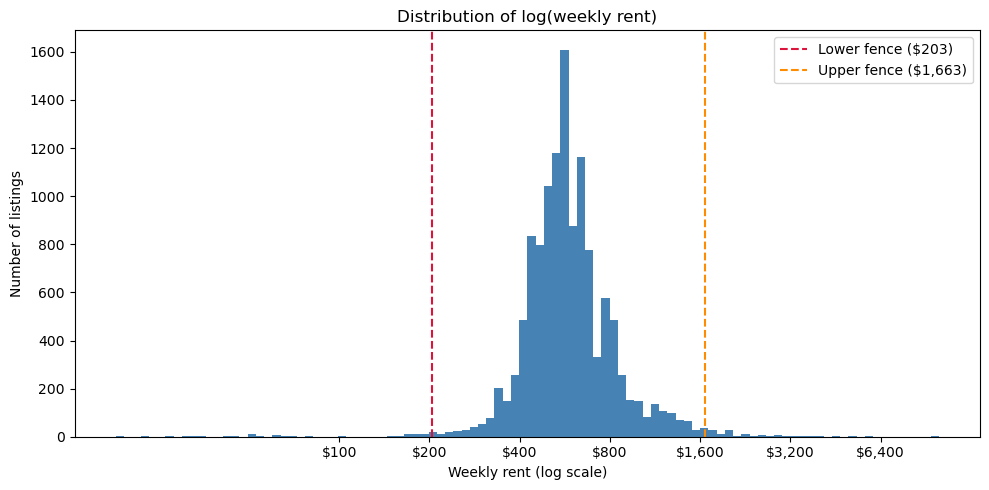

In [79]:
import numpy as np
import matplotlib.pyplot as plt

log_rent = df_iqr.select("log_rent").toPandas()["log_rent"]

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(log_rent, bins=100, color="steelblue", edgecolor="none")

ax.axvline(lower_fence, color="crimson", ls="--", lw=1.5,
           label=f"Lower fence (${np.exp(lower_fence):,.0f})")
ax.axvline(upper_fence, color="darkorange", ls="--", lw=1.5,
           label=f"Upper fence (${np.exp(upper_fence):,.0f})")

# Dollar values on the x-axis, for easier reading
ticks = [100, 200, 400, 800, 1600, 3200, 6400]
ax.set_xticks(np.log(ticks))
ax.set_xticklabels([f"${t:,}" for t in ticks])

ax.set_title("Distribution of log(weekly rent)")
ax.set_xlabel("Weekly rent (log scale)")
ax.set_ylabel("Number of listings")
ax.legend()
plt.tight_layout()
plt.show()

In [80]:
review_cols = ["listing_id", "suburb", "primary_type", "bedrooms", "weekly_rent", "url"]

print("=== Low outliers ===")
df_iqr.filter(F.col("iqr_flag") == "low_outlier").select(review_cols) \
    .orderBy("weekly_rent").show(100, vertical=True, truncate=False)

print("=== High outliers ===")
df_iqr.filter(F.col("iqr_flag") == "high_outlier").select(review_cols) \
    .orderBy(F.desc("weekly_rent")).show(100, vertical=True, truncate=False)

=== Low outliers ===
-RECORD 0---------------------------------------------------------------------------------------------------
 listing_id   | 13243113                                                                                    
 suburb       | TONGALA                                                                                     
 primary_type | House                                                                                       
 bedrooms     | NULL                                                                                        
 weekly_rent  | 18.0                                                                                        
 url          | https://www.domain.com.au/5-greiner-court-tongala-vic-3621-13243113                         
-RECORD 1---------------------------------------------------------------------------------------------------
 listing_id   | 12352715                                                                                   

And so, let us **remove** the 86 low end outliers now.

In [81]:
# Remove low-end rent outliers (below the lower IQR fence)
n_before = df_curated_one.count()

df_curated_one = df_curated_one.filter(F.log("weekly_rent") >= lower_fence)

n_after = df_curated_one.count()
print(f"Removed {n_before - n_after} low-end outliers "
      f"(weekly_rent < ${math.exp(lower_fence):,.0f}/week)")
print(f"Rows: {n_before:,} -> {n_after:,}")

Removed 86 low-end outliers (weekly_rent < $203/week)
Rows: 12,411 -> 12,325


Furthermore, lets manually investigate particularly high outlier `weekly_rent` values to ensure they are legitimate.

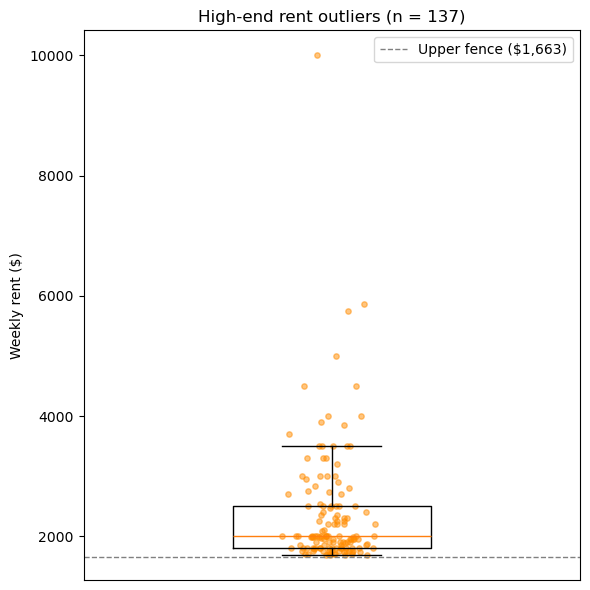

In [82]:
import numpy as np
import matplotlib.pyplot as plt

high_rents = df_iqr.filter(F.col("iqr_flag") == "high_outlier") \
    .select("weekly_rent").toPandas()["weekly_rent"]

fig, ax = plt.subplots(figsize=(6, 6))

ax.boxplot(high_rents, vert=True, widths=0.4, showfliers=False)

# Each listing as a jittered dot, so you can see how they spread
jitter = np.random.normal(1, 0.04, size=len(high_rents))
ax.scatter(jitter, high_rents, alpha=0.5, s=15, color="darkorange")

ax.axhline(np.exp(upper_fence), color="grey", ls="--", lw=1,
           label=f"Upper fence (${np.exp(upper_fence):,.0f})")

ax.set_title(f"High-end rent outliers (n = {len(high_rents)})")
ax.set_ylabel("Weekly rent ($)")
ax.set_xticks([])
ax.legend()
plt.tight_layout()
plt.show()

In [83]:
high_pdf = df_iqr.filter(F.col("iqr_flag") == "high_outlier") \
    .select("listing_id", "suburb", "primary_type", "bedrooms",
            "weekly_rent", "bond", "url").toPandas()

q1_h, q3_h = high_pdf["weekly_rent"].quantile([0.25, 0.75])
whisker = q3_h + 1.5 * (q3_h - q1_h)

above = high_pdf[high_pdf["weekly_rent"] > whisker] \
    .sort_values("weekly_rent", ascending=False)

print(f"Upper whisker within high outliers: ${whisker:,.0f}/week")
print(f"Listings above it: {len(above)}")
above

Upper whisker within high outliers: $3,550/week
Listings above it: 11


,listing_id,suburb,primary_type,bedrooms,weekly_rent,bond,url
87,17712191,TOORAK,House,6.0,10000.0,60000.0,https://www.domain.com.au/toorak-vic-3142-1771...
113,17661725,CAMBERWELL,House,5.0,5866.0,5866.0,https://www.domain.com.au/54-fairmont-avenue-c...
88,17722803,TOORAK,House,4.0,5750.0,34500.0,https://www.domain.com.au/2-lisbuoy-court-toor...
129,9287841,BRIGHTON,Apartment,5.0,5000.0,NaN,https://www.domain.com.au/brighton-vic-3186-92...
67,17744678,HAWTHORN,House,5.0,4500.0,27000.0,https://www.domain.com.au/94-illawarra-road-ha...
99,17694334,SOUTH YARRA,Apartment,3.0,4500.0,27000.0,https://www.domain.com.au/1-fairlie-court-sout...
5,17460975,SOUTH MELBOURNE,Apartment,4.0,4000.0,24000.0,https://www.domain.com.au/901-161-eastern-road...
119,17750966,BRIGHTON,House,4.0,4000.0,24000.0,https://www.domain.com.au/74-champion-street-b...
9,14253235,PORT MELBOURNE,Townhouse/Villa,4.0,3900.0,23400.0,https://www.domain.com.au/1-tarver-st-port-mel...
26,17721041,CREMORNE,House,4.0,3850.0,15400.0,https://www.domain.com.au/13-balmain-st-cremor...


Upon our manual inspection of every high-end listing above the box-plot whisker (done by serching the property listing online), we find that `listing_id` = 17661725 is the only listing that has a false `weekly_rent` value. Since its true `weekly_rent` cannon't reliably be infered we will remove this row aswell.

In [84]:
# --- Remove a high-end listing confirmed as misparsed after manual review ---
n_before = df_curated_one.count()

df_curated_one = df_curated_one.filter(F.col("listing_id") != 17661725)

print(f"Removed {n_before - df_curated_one.count()} listing (listing_id = 17661725)")
print(f"Rows: {n_before:,} -> {df_curated_one.count():,}")

Removed 1 listing (listing_id = 17661725)
Rows: 12,325 -> 12,324


Lets persist what we have done for `weekly_values` and Non-Residential buildings for ease of use for further data cleaning.

In [86]:
# Save the cleaned DataFrame to Parquet format
output_path = "../../rea_data/curated/vic_rentals_curated_2.parquet"

df_curated_one.write.mode("overwrite").parquet(output_path)

print(f"Shape: {df_curated_one.count():,} rows, {len(df_curated_one.columns)} columns")

Shape: 12,324 rows, 84 columns
